# Лабораторная работа №4
## Численное решение обыкновенных дифференциальных уравнений
### Вариант 5

В работе используются функции `solve_ivp` и `solve_bvp` из `scipy.integrate`.

## Задание 1. Задача Коши

На отрезке `[0, 2]` найти приближенное решение задачи Коши:

$$y''' + 4y'' + 4\cos(y') + y = 2e^t,$$

$$y(0)=0,\qquad y'(0)=1,\qquad y''(0)=1.$$

Введем переменные $z_1=y$, $z_2=y'$, $z_3=y''$. Тогда уравнение сводится к системе первого порядка:

$$z_1'=z_2,\qquad z_2'=z_3,$$
$$z_3'=2e^t-4z_3-4\cos(z_2)-z_1.$$

Начальное условие для системы имеет вид $z(0)=(0,1,1)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

In [2]:
def cauchy_system(t, z):
    y, dy, ddy = z
    return np.array([
        dy,
        ddy,
        2 * np.exp(t) - 4 * ddy - 4 * np.cos(dy) - y,
    ])

t_eval = np.linspace(0.0, 2.0, 401)
initial_values = np.array([0.0, 1.0, 1.0])
cauchy_solution = solve_ivp(
    cauchy_system,
    (0.0, 2.0),
    initial_values,
    t_eval=t_eval,
    method='RK45',
    rtol=1e-9,
    atol=1e-11,
)

if not cauchy_solution.success:
    raise RuntimeError(cauchy_solution.message)

y, dy, ddy = cauchy_solution.y
print(f'Число узлов: {len(cauchy_solution.t)}')
print(f'y(2) = {y[-1]:.10f}')
print(f"Невязки начальных условий: |y(0)| = {abs(y[0]):.2e}, "
      f'|y\'(0)-1| = {abs(dy[0] - 1):.2e}, '
      f'|y\'\'(0)-1| = {abs(ddy[0] - 1):.2e}')

Число узлов: 401
y(2) = 3.3609047338
Невязки начальных условий: |y(0)| = 0.00e+00, |y'(0)-1| = 0.00e+00, |y''(0)-1| = 0.00e+00


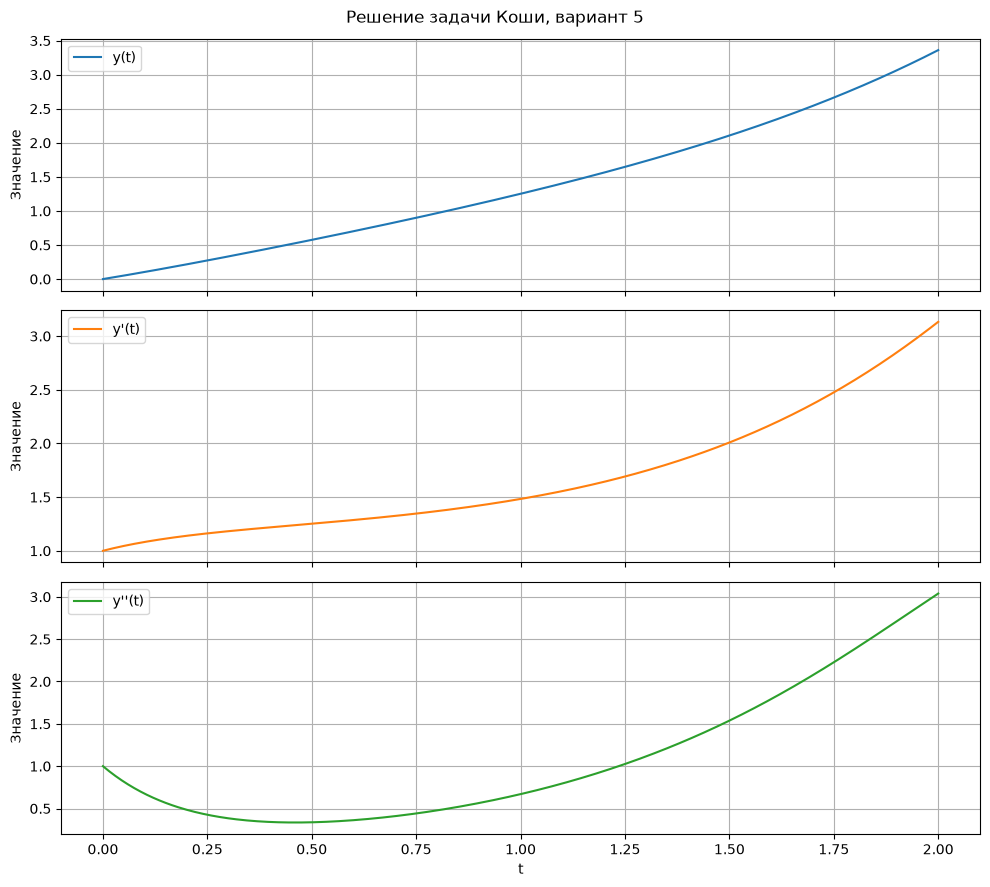

In [3]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 9))
axes[0].plot(cauchy_solution.t, y, label='y(t)', color='tab:blue')
axes[1].plot(cauchy_solution.t, dy, label="y'(t)", color='tab:orange')
axes[2].plot(cauchy_solution.t, ddy, label="y''(t)", color='tab:green')
for ax in axes:
    ax.legend()
    ax.set_ylabel('Значение')
axes[-1].set_xlabel('t')
fig.suptitle('Решение задачи Коши, вариант 5')
plt.tight_layout()
plt.show()

## Задание 2. Краевая задача

На интервале $1/2 < x < 1$ найти приближенное решение:

$$u'' + (x-1)u' - 2u = x^3 - 3x^2 + 5x - 1,$$

$$4u\left(\frac12\right)-u'\left(\frac12\right)=\frac34,\qquad u(1)=2.$$

Положим $v_1=u$, $v_2=u'$. Получаем систему:

$$v_1'=v_2,$$
$$v_2'=x^3-3x^2+5x-1-(x-1)v_2+2v_1.$$

Граничные невязки для `solve_bvp`:

$$B_1(v(1/2),v(1))=4v_1(1/2)-v_2(1/2)-\frac34,$$
$$B_2(v(1/2),v(1))=v_1(1)-2.$$

In [4]:
def boundary_system(x, v):
    u, du = v
    forcing = x**3 - 3 * x**2 + 5 * x - 1
    return np.vstack((du, forcing - (x - 1) * du + 2 * u))


def boundary_conditions(left, right):
    return np.array([
        4 * left[0] - left[1] - 3 / 4,
        right[0] - 2,
    ])

x_mesh = np.linspace(0.5, 1.0, 80)
initial_guess = np.zeros((2, x_mesh.size))
initial_guess[0] = 2.0
initial_guess[1] = 1.0

boundary_solution = solve_bvp(
    boundary_system,
    boundary_conditions,
    x_mesh,
    initial_guess,
    tol=1e-8,
    max_nodes=10000,
)

if not boundary_solution.success:
    raise RuntimeError(boundary_solution.message)

x_plot = np.linspace(0.5, 1.0, 400)
u_plot, du_plot = boundary_solution.sol(x_plot)
left_value = boundary_solution.sol(0.5)
right_value = boundary_solution.sol(1.0)
bc_residuals = boundary_conditions(left_value, right_value)

print(f'Число узлов после адаптации: {boundary_solution.x.size}')
print(f'u(1/2) = {left_value[0]:.10f}, u\'(1/2) = {left_value[1]:.10f}')
print(f'u(1) = {right_value[0]:.10f}')
print(f'Невязки граничных условий: {np.abs(bc_residuals)}')

Число узлов после адаптации: 80
u(1/2) = 0.6250000000, u'(1/2) = 1.7500000000
u(1) = 2.0000000000
Невязки граничных условий: [0. 0.]


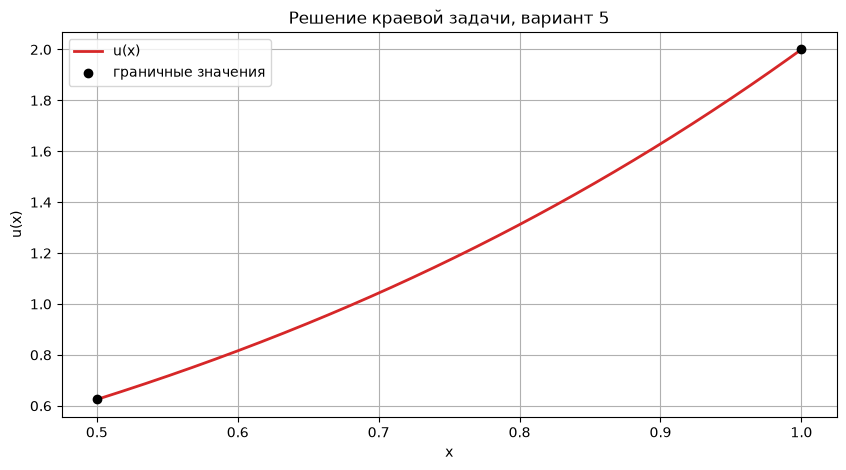

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(x_plot, u_plot, label='u(x)', color='tab:red', linewidth=2)
plt.scatter([0.5, 1.0], [left_value[0], right_value[0]], color='black', zorder=3,
            label='граничные значения')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Решение краевой задачи, вариант 5')
plt.legend()
plt.show()